# Этап 1. Знакомство с данными и EDA

В этой части загрузим данные Goodbooks-10k и посмотрим на распределение оценок, активность пользователей, популярность книг и частые теги.

In [227]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('ggplot')

# Все файлы находятся в папке data рядом с ноутбуком.
ratings = pd.read_csv('data/ratings.csv')
books = pd.read_csv('data/books.csv')
# В ratings.csv book_id соответствует колонке id из books.csv.
# В book_tags.csv используется Goodreads ID из колонки book_id.
books = books.rename(columns={'id': 'book_id', 'book_id': 'goodreads_book_id'})
tags = pd.read_csv('data/tags.csv')
book_tags = pd.read_csv('data/book_tags.csv')

print('ratings:', ratings.shape)
print('books:', books.shape)
print('tags:', tags.shape)
print('book_tags:', book_tags.shape)

display(ratings.head())
display(books[['book_id', 'title', 'authors', 'average_rating']].head())
display(tags.head())
display(book_tags.head())

ratings: (981756, 3)
books: (10000, 23)
tags: (34252, 2)
book_tags: (999912, 3)


,book_id,user_id,rating
0,1,314,5
1,1,439,3
2,1,588,5
3,1,1169,4
4,1,1185,4


,book_id,title,authors,average_rating
0,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,4.34
1,2,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",4.44
2,3,"Twilight (Twilight, #1)",Stephenie Meyer,3.57
3,4,To Kill a Mockingbird,Harper Lee,4.25
4,5,The Great Gatsby,F. Scott Fitzgerald,3.89


,tag_id,tag_name
0,0,-
1,1,--1-
2,2,--10-
3,3,--12-
4,4,--122-


,goodreads_book_id,tag_id,count
0,1,30574,167697
1,1,11305,37174
2,1,11557,34173
3,1,8717,12986
4,1,33114,12716


## 1. Распределение оценок

Средняя оценка: 3.86
Медианная оценка: 4.0


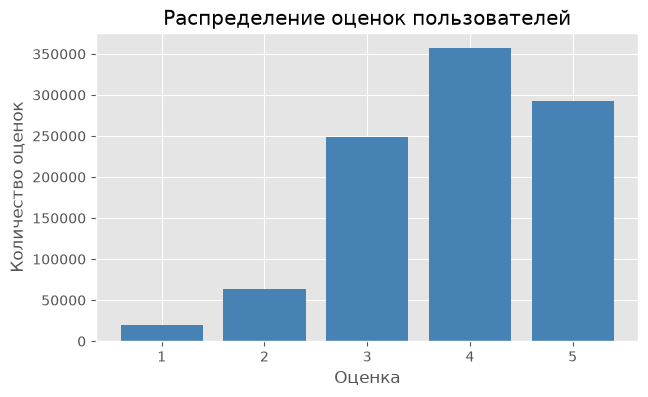

,number_of_ratings
rating,
1,19575
2,63231
3,248623
4,357366
5,292961


In [228]:
rating_counts = ratings['rating'].value_counts().sort_index()
print('Средняя оценка:', round(ratings['rating'].mean(), 2))
print('Медианная оценка:', ratings['rating'].median())

plt.figure(figsize=(7, 4))
plt.bar(rating_counts.index, rating_counts.values, color='steelblue')
plt.title('Распределение оценок пользователей')
plt.xlabel('Оценка')
plt.ylabel('Количество оценок')
plt.xticks(rating_counts.index)
plt.show()

rating_counts.to_frame('number_of_ratings')

По графику можно проверить, есть ли смещение оценок к 4 и 5. Если высокие оценки встречаются намного чаще низких, это важно учитывать при обучении моделей: средняя оценка книги может выглядеть завышенной.

## 2. Активность пользователей

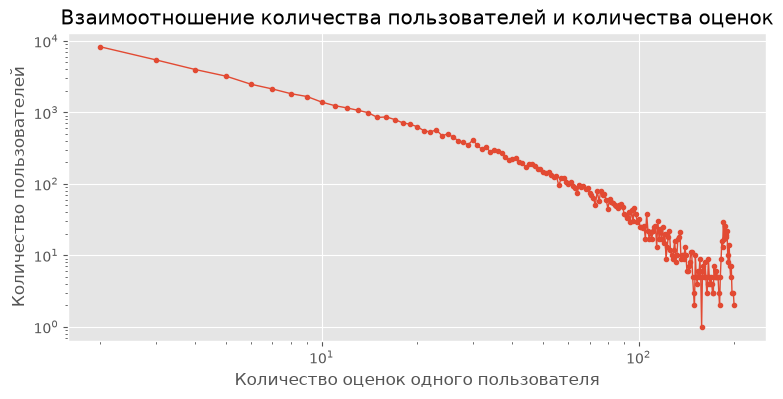

Количество пользователей: 53424
Среднее количество оценок на пользователя: 18.38
Медианное количество оценок на пользователя: 8.0
Самые активные пользователи:


user_id
12874    200
30944    200
52036    199
12381    199
28158    199
6630     197
45554    197
37834    197
24143    196
9668     196
Name: number_of_ratings, dtype: int64

Пользователи не более чем с 5 оценками: 20926
Доля таких пользователей: 39.17 %


In [229]:
ratings_per_user = ratings.groupby('user_id').size()
user_activity = ratings_per_user.value_counts().sort_index()

# По оси X — сколько оценок оставил пользователь, по оси Y — сколько таких пользователей.
plt.figure(figsize=(9, 4))
plt.plot(user_activity.index, user_activity.values, marker='.', linewidth=1)
plt.title('Взаимоотношение количества пользователей и количества оценок')
plt.xlabel('Количество оценок одного пользователя')
plt.ylabel('Количество пользователей')
plt.xscale('log')
plt.yscale('log')
plt.show()

print('Количество пользователей:', ratings['user_id'].nunique())
print('Среднее количество оценок на пользователя:', round(ratings_per_user.mean(), 2))
print('Медианное количество оценок на пользователя:', ratings_per_user.median())

print('Самые активные пользователи:')
display(ratings_per_user.sort_values(ascending=False).head(10).rename('number_of_ratings'))

low_activity_users = (ratings_per_user <= 5).sum()
print('Пользователи не более чем с 5 оценками:', low_activity_users)
print('Доля таких пользователей:', round(low_activity_users / len(ratings_per_user) * 100, 2), '%')

Распределение активности обычно имеет длинный хвост: небольшая группа пользователей оставляет много оценок, а у большого числа пользователей взаимодействий мало. Пользователи с одной или несколькими оценками — пример холодного старта для персональных рекомендаций.

## 3. Популярность книг

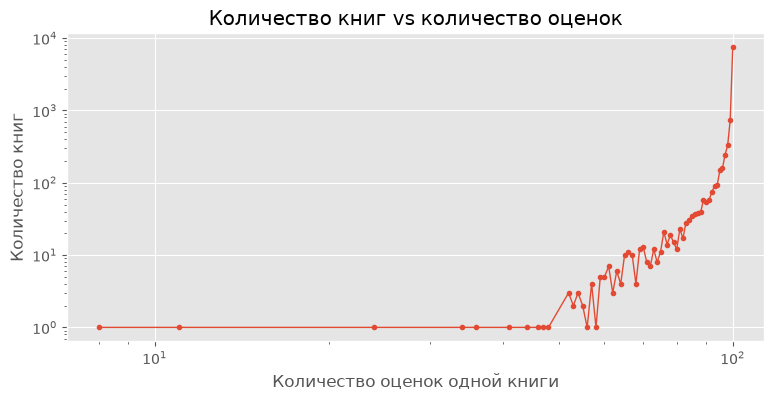

,book_id,title,number_of_ratings
0,1,"The Hunger Games (The Hunger Games, #1)",100
1,5198,Of Love and Shadows,100
2,5215,Plan B: Further Thoughts on Faith,100
3,5214,"The Archer's Tale (The Grail Quest, #1)",100
4,9803,The Berenstain Bears and Too Much TV,100
5,5211,Pay It Forward,100
6,5210,Discipline and Punish: The Birth of the Prison,100
7,5209,"Odd Apocalypse (Odd Thomas, #5)",100
8,5207,The Days Are Just Packed: A Calvin and Hobbes ...,100
9,5206,Sick Puppy,100


Книг не более чем с 20 оценками: 2
Максимальное число оценок у одной книги: 100


In [230]:
ratings_per_book = ratings.groupby('book_id').size()
book_popularity = ratings_per_book.value_counts().sort_index()

# На графике виден длинный хвост книг с небольшим числом оценок.
plt.figure(figsize=(9, 4))
plt.plot(book_popularity.index, book_popularity.values, marker='.', linewidth=1)
plt.title('Количество книг vs количество оценок')
plt.xlabel('Количество оценок одной книги')
plt.ylabel('Количество книг')
plt.xscale('log')
plt.yscale('log')
plt.show()

popular_books = ratings_per_book.sort_values(ascending=False).head(10).rename('number_of_ratings').reset_index()
popular_books = popular_books.merge(books[['book_id', 'title']], on='book_id', how='left')
display(popular_books[['book_id', 'title', 'number_of_ratings']])

low_popularity_books = (ratings_per_book <= 20).sum()
print('Книг не более чем с 20 оценками:', low_popularity_books)
print('Максимальное число оценок у одной книги:', ratings_per_book.max())

Небольшое число книг получает большую часть оценок, а многие книги почти не представлены в пользовательских взаимодействиях. Это проявление смещения популярности и одновременно проблема разреженности матрицы пользователь–книга.

## 4. Самые частые теги

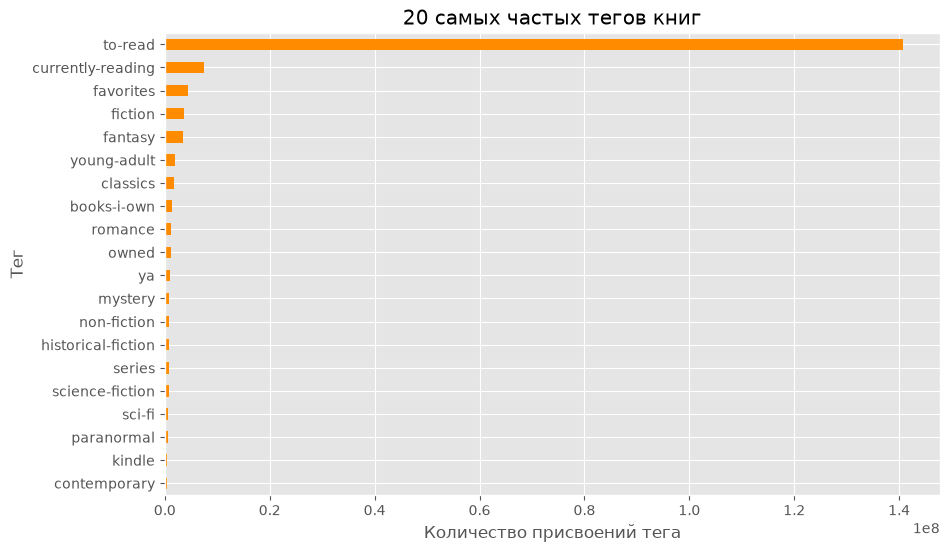

,tag_count
tag_name,
to-read,140718761
currently-reading,7507958
favorites,4503173
fiction,3688819
fantasy,3548157
young-adult,1848306
classics,1756920
books-i-own,1317235
romance,1231926


In [231]:
# В book_tags хранится tag_id, поэтому сначала добавим название тега из tags.
book_tags_with_names = book_tags.merge(tags, on='tag_id', how='left')

# count показывает, сколько раз тег был присвоен книгам пользователями.
tag_popularity = (
    book_tags_with_names.groupby('tag_name')['count']
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

plt.figure(figsize=(10, 6))
tag_popularity.sort_values().plot(kind='barh', color='darkorange')
plt.title('20 самых частых тегов книг')
plt.xlabel('Количество присвоений тега')
plt.ylabel('Тег')
plt.show()

display(tag_popularity.to_frame('tag_count'))

## 5. Разреженность матрицы пользователь–книга

In [232]:
number_of_users = ratings['user_id'].nunique()
number_of_books = books['book_id'].nunique()
number_of_ratings = len(ratings)
possible_interactions = number_of_users * number_of_books
sparsity = 1 - number_of_ratings / possible_interactions

print('Всего возможных пар пользователь–книга:', f'{possible_interactions:,}')
print('Наблюдаемых оценок:', f'{number_of_ratings:,}')
print('Разреженность матрицы:', round(sparsity * 100, 2), '%')

Всего возможных пар пользователь–книга: 534,240,000
Наблюдаемых оценок: 981,756
Разреженность матрицы: 99.82 %


## Выводы по EDA

1. В оценках заметно смещение к высоким значениям: оценки 4 и 5 встречаются чаще низких. Поэтому средняя оценка книги может выглядеть завышенной.
2. Активность пользователей распределена неравномерно: есть небольшая группа очень активных пользователей и много пользователей с малым числом оценок. Для последних персональные рекомендации строить сложнее.
3. У книг есть длинный хвост по числу оценок, но в этом файле максимум равен 100 оценкам на книгу. Поэтому популярность в ratings.csv ограничена способом формирования выборки, и это нужно учитывать при сравнении книг.
4. Матрица пользователь–книга сильно разрежена: число возможных взаимодействий намного больше числа наблюдаемых оценок. Поэтому коллаборативные методы могут плохо работать для новых пользователей и редко оцениваемых книг.
5. Частые теги можно использовать в контентной модели: они дают дополнительное описание книги и помогают рекомендовать книги при недостатке пользовательской истории.

# Этап 2. Базовые и контентные модели

Сначала построим простой неперсонализированный бейзлайн, затем используем названия книг и теги для поиска похожих книг.

## 1. Top-N популярных книг

In [233]:
def get_popular_books(n=10, min_ratings=50):
    """Возвращает N книг с самым высоким средним рейтингом."""
    book_stats = (
        ratings.groupby('book_id')['rating']
        .agg(['mean', 'count'])
        .reset_index()
        .rename(columns={'mean': 'average_rating', 'count': 'number_of_ratings'})
    )

    popular_books = book_stats[book_stats['number_of_ratings'] >= min_ratings]
    popular_books = popular_books.sort_values(
        ['average_rating', 'number_of_ratings'],
        ascending=[False, False]
    )

    return (
        popular_books.head(n)
        .merge(books[['book_id', 'title', 'authors']], on='book_id', how='left')
        [['book_id', 'title', 'authors', 'average_rating', 'number_of_ratings']]
    )

# Минимальный порог защищает от книг с высоким рейтингом на слишком малом числе оценок.
popular_books = get_popular_books(n=10, min_ratings=50)
popular_books

,book_id,title,authors,average_rating,number_of_ratings
0,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",4.820225,89
1,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson,4.780000,100
2,6920,The Indispensable Calvin and Hobbes,Bill Watterson,4.780000,100
3,9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson,4.777778,99
4,8946,The Divan,Hafez,4.774194,93
5,3275,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré",4.770000,100
6,6361,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson,4.770000,100
7,4483,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson,4.750000,100
8,5580,The Calvin and Hobbes Lazy Sunday Book,Bill Watterson,4.750000,100
9,6590,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson,4.750000,100


Этот бейзлайн одинаков для всех пользователей. Он полезен как точка отсчёта: более сложная персональная модель должна сравниваться с ним на тех же данных. Параметр `min_ratings` уменьшает влияние случайно высоких оценок у книг с малым числом взаимодействий.

## 2. TF-IDF-профили книг

In [234]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# У одной книги может быть много строк в book_tags, поэтому объединим теги в одну строку.
tags_by_book = (
    book_tags.merge(tags, on='tag_id', how='left')
    .groupby('goodreads_book_id')['tag_name']
    .apply(lambda values: ' '.join(values.astype(str)))
    .rename('tags_text')
)

book_profiles = books[['book_id', 'goodreads_book_id', 'title', 'original_title', 'authors']].copy()
book_profiles = book_profiles.merge(
    tags_by_book,
    left_on='goodreads_book_id',
    right_index=True,
    how='left'
)
# В датасете часть original_title записана как пустая строка.
# Для таких книг используем обычное title.
book_profiles['original_title'] = book_profiles['original_title'].replace(r'^\s*$', pd.NA, regex=True)
book_profiles['title'] = book_profiles['title'].replace(r'^\s*$', pd.NA, regex=True)
book_profiles['authors'] = book_profiles['authors'].replace(r'^\s*$', pd.NA, regex=True)
book_profiles['original_title'] = book_profiles['original_title'].fillna(book_profiles['title']).fillna('')
book_profiles['authors'] = book_profiles['authors'].fillna('')
book_profiles['tags_text'] = book_profiles['tags_text'].fillna('')

# Текстовый профиль состоит из названия книги и всех её тегов.
book_profiles['profile'] = (
    book_profiles['original_title'] + ' ' + book_profiles['authors'] + ' ' + book_profiles['tags_text']
).str.lower()

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(book_profiles['profile'])
book_id_to_index = pd.Series(book_profiles.index, index=book_profiles['book_id'])

print('Размер TF-IDF матрицы:', tfidf_matrix.shape)
print('Книг с пустым original_title:', books['original_title'].fillna('').str.strip().eq('').sum())
display(book_profiles[['book_id', 'original_title', 'tags_text', 'profile']].head())

Размер TF-IDF матрицы: (10000, 24106)
Книг с пустым original_title: 590


,book_id,original_title,tags_text,profile
0,1,The Hunger Games,favorites currently-reading young-adult fictio...,the hunger games suzanne collins favorites cur...
1,2,Harry Potter and the Philosopher's Stone,to-read favorites fantasy currently-reading yo...,harry potter and the philosopher's stone j.k. ...
2,3,Twilight,young-adult fantasy favorites vampires ya fict...,twilight stephenie meyer young-adult fantasy f...
3,4,To Kill a Mockingbird,classics favorites to-read classic historical-...,to kill a mockingbird harper lee classics favo...
4,5,The Great Gatsby,classics favorites fiction classic books-i-own...,the great gatsby f. scott fitzgerald classics ...


In [235]:
def get_similar_books(book_id, N=5):
    """Возвращает N книг, наиболее похожих на книгу book_id."""
    if book_id not in book_id_to_index.index:
        raise ValueError('Книга с таким book_id не найдена')

    book_index = book_id_to_index.loc[book_id]
    similarities = cosine_similarity(tfidf_matrix[book_index], tfidf_matrix).ravel()
    similar_indices = similarities.argsort()[::-1]

    # Первая книга в списке — исходная, поэтому исключаем её.
    similar_indices = [index for index in similar_indices if index != book_index][:N]

    result = book_profiles.iloc[similar_indices][['book_id', 'original_title']].copy()
    result['similarity'] = similarities[similar_indices]
    return result.reset_index(drop=True)

# Пример: книги, похожие на книгу с book_id = 1.
get_similar_books(book_id=1, N=5)

,book_id,original_title,similarity
0,20,Mockingjay,0.936035
1,17,Catching Fire,0.930881
2,507,The Hunger Games Box Set,0.918113
3,717,The Hunger Games: Official Illustrated Movie C...,0.662771
4,1355,The Hunger Games Tribute Guide,0.661245


Контентная модель сравнивает книги по общим словам в названии и тегах. Она не использует историю конкретного пользователя, поэтому может работать для новой книги, если у неё есть название или теги.

# Этап 3. Коллаборативная фильтрация

## 1. Матрица взаимодействий пользователь–книга

In [236]:
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

# Переводим исходные id в последовательные индексы строк и столбцов.
user_ids = ratings['user_id'].unique()
book_ids = ratings['book_id'].unique()
user_id_to_index = {user_id: index for index, user_id in enumerate(user_ids)}
book_id_to_index_cf = {book_id: index for index, book_id in enumerate(book_ids)}

row_indices = ratings['user_id'].map(user_id_to_index)
column_indices = ratings['book_id'].map(book_id_to_index_cf)

# В ячейках хранятся явные оценки пользователей. Нули означают отсутствие оценки.
interaction_matrix = csr_matrix(
    (ratings['rating'], (row_indices, column_indices)),
    shape=(len(user_ids), len(book_ids))
)

print('Размер матрицы:', interaction_matrix.shape)
print('Количество ненулевых оценок:', interaction_matrix.nnz)
print('Доля заполненных ячеек:', round(interaction_matrix.nnz / interaction_matrix.shape[0] / interaction_matrix.shape[1] * 100, 4), '%')

Размер матрицы: (53424, 10000)
Количество ненулевых оценок: 979478
Доля заполненных ячеек: 0.1833 %


Используем явные оценки, потому что в датасете они уже есть. Разреженный формат хранит только наблюдаемые оценки и экономит память по сравнению с обычной плотной таблицей.

## 2. Item-Based Collaborative Filtering

In [237]:
# Для item-based CF сравниваем столбцы матрицы, то есть векторы оценок книг.
# dense_output=False оставляет результат в разреженном формате.
item_similarity = cosine_similarity(
    interaction_matrix.T,
    dense_output=False
)

print('Размер матрицы схожести:', item_similarity.shape)
print('Ненулевых значений схожести:', item_similarity.nnz)

Размер матрицы схожести: (10000, 10000)
Ненулевых значений схожести: 24377518


In [238]:
def predict_rating(user_id, book_id, K=5):
    """Предсказывает оценку книги по K похожим книгам пользователя."""
    if user_id not in user_id_to_index:
        raise ValueError('Пользователь с таким user_id не найден')
    if book_id not in book_id_to_index_cf:
        raise ValueError('Книга с таким book_id не найдена')

    user_index = user_id_to_index[user_id]
    book_index = book_id_to_index_cf[book_id]
    rated_book_indices = interaction_matrix.getrow(user_index).indices
    rated_book_indices = rated_book_indices[rated_book_indices != book_index]

    if len(rated_book_indices) == 0:
        return ratings['rating'].mean()

    similarities = item_similarity[book_index, rated_book_indices].toarray().ravel()
    order = np.argsort(similarities)[::-1]
    top_indices = rated_book_indices[order[:K]]
    top_similarities = similarities[order[:K]]
    top_ratings = interaction_matrix[user_index, top_indices].toarray().ravel()

    # Если общих похожих книг нет, используем среднюю оценку пользователя.
    if top_similarities.sum() == 0:
        return interaction_matrix.getrow(user_index).data.mean()

    # Взвешенное среднее: более похожие книги сильнее влияют на прогноз.
    return np.dot(top_similarities, top_ratings) / top_similarities.sum()

# Пример прогноза для первой пары из датасета.
example_user_id = ratings.iloc[0]['user_id']
example_book_id = ratings.iloc[0]['book_id']
print('Пользователь:', example_user_id)
print('Книга:', example_book_id)
print('Предсказанная оценка:', round(predict_rating(example_user_id, example_book_id, K=5), 2))

Пользователь: 314
Книга: 1
Предсказанная оценка: 4.02


## 3. Вычислительная сложность и ограничения

Пусть U — число пользователей, I — число книг, а R — число наблюдаемых оценок. Построение полной матрицы схожести книг в наивном варианте требует примерно O(I² · U) операций и O(I²) памяти. Для больших каталогов это становится узким местом.

Оптимизации:
- хранить матрицу взаимодействий в разреженном формате;
- вычислять и хранить только K ближайших соседей для каждой книги;
- считать схожести offline и обновлять их периодически;
- использовать матричные операции и approximate nearest neighbors;
- для очень больших данных перейти к матричной факторизации, например SVD.

Основные ограничения item-based CF — проблема холодного старта для новых книг, зависимость от количества общих оценок и смещение в сторону популярных книг.

# Этап 4. Матричные разложения

## 1. Обучение SVD и оценка RMSE

In [239]:
from surprise import Dataset, Reader, SVD, accuracy
from surprise.model_selection import train_test_split

# Surprise ожидает таблицу с колонками user, item, rating.
reader = Reader(rating_scale=(1, 5))
surprise_data = Dataset.load_from_df(
    ratings[['user_id', 'book_id', 'rating']],
    reader
)

trainset, testset = train_test_split(
    surprise_data,
    test_size=0.2,
    random_state=42
)

svd_model = SVD(
    n_factors=50,
    n_epochs=20,
    random_state=42
)
svd_model.fit(trainset)

test_predictions = svd_model.test(testset)
rmse = accuracy.rmse(test_predictions, verbose=True)
print('RMSE на тестовой выборке:', round(rmse, 4))

RMSE: 0.8402
RMSE на тестовой выборке: 0.8402


RMSE показывает среднюю ошибку предсказания рейтинга в тех же единицах, что и исходная оценка. Чем меньше значение RMSE, тем точнее модель предсказывает оценки на тестовой выборке.

## 2. Рекомендации для пользователя

In [240]:
def get_recommendations(user_id, N=5):
    """Возвращает N книг с максимальным предсказанным рейтингом."""
    if user_id not in ratings['user_id'].values:
        raise ValueError('Пользователь с таким user_id не найден')

    rated_book_ids = set(ratings.loc[ratings['user_id'] == user_id, 'book_id'])
    candidate_book_ids = [
        book_id for book_id in books['book_id']
        if book_id not in rated_book_ids
    ]

    predictions = [
        {'book_id': book_id, 'predicted_rating': svd_model.predict(user_id, book_id).est}
        for book_id in candidate_book_ids
    ]

    recommendations = pd.DataFrame(predictions)
    recommendations = recommendations.sort_values(
        'predicted_rating', ascending=False
    ).head(N)

    return (
        recommendations.merge(
            books[['book_id', 'title', 'authors']],
            on='book_id',
            how='left'
        )
        [['book_id', 'title', 'authors', 'predicted_rating']]
        .reset_index(drop=True)
    )

# Пример рекомендаций для пользователя из первой строки датасета.
example_user_id = ratings.iloc[0]['user_id']
get_recommendations(example_user_id, N=5)

,book_id,title,authors,predicted_rating
0,6590,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson,4.620692
1,3628,The Complete Calvin and Hobbes,Bill Watterson,4.592681
2,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson,4.573909
3,862,"Words of Radiance (The Stormlight Archive, #2)",Brandon Sanderson,4.562590
4,1788,The Calvin and Hobbes Tenth Anniversary Book,Bill Watterson,4.534648


SVD использует скрытые факторы пользователей и книг. В отличие от item-based CF, модель не хранит полную матрицу схожести между всеми книгами, поэтому хорошо подходит для более масштабируемого предсказания оценок. Однако для нового пользователя или книги без истории сохраняется проблема холодного старта.

# Этап 5. Оценка и сравнение моделей

## 1. Подготовка отложенной выборки

In [241]:
# Если предыдущие ячейки были запущены до исправления идентификаторов,
# нормализуем books и здесь тоже.
if 'goodreads_book_id' not in books.columns:
    books = books.rename(columns={'id': 'book_id', 'book_id': 'goodreads_book_id'})

# Используем то же разбиение, на котором считали RMSE для SVD.
train_ratings_eval = pd.DataFrame(
    trainset.build_testset(),
    columns=['user_id', 'book_id', 'rating']
)
test_ratings_eval = pd.DataFrame(
    testset,
    columns=['user_id', 'book_id', 'rating']
)

relevant_test = test_ratings_eval[test_ratings_eval['rating'] >= 4]
relevant_by_user = (
    relevant_test.groupby('user_id')['book_id']
    .apply(set)
    .to_dict()
)

# Для скорости оцениваем одинаковую фиксированную подвыборку пользователей.
EVAL_USER_LIMIT = 500
rng = np.random.RandomState(42)
train_users_for_eval = set(train_ratings_eval['user_id'])
evaluation_users = [
    user_id for user_id in relevant_by_user
    if user_id in train_users_for_eval
]
excluded_cold_start_users = len(relevant_by_user) - len(evaluation_users)
if len(evaluation_users) > EVAL_USER_LIMIT:
    evaluation_users = rng.choice(
        evaluation_users,
        size=EVAL_USER_LIMIT,
        replace=False
    ).tolist()

print('Пользователей с релевантными книгами в тесте:', len(relevant_by_user))
print('Исключено пользователей без истории в train:', excluded_cold_start_users)
print('Пользователей используется для оценки:', len(evaluation_users))
print('Порог релевантности:', 'rating >= 4')

Пользователей с релевантными книгами в тесте: 34779
Исключено пользователей без истории в train: 355
Пользователей используется для оценки: 500
Порог релевантности: rating >= 4


In [242]:
def precision_at_k(recommended, relevant, k):
    recommended = recommended[:k]
    return len(set(recommended) & set(relevant)) / k


def recall_at_k(recommended, relevant, k):
    recommended = recommended[:k]
    return len(set(recommended) & set(relevant)) / len(relevant)


def ndcg_at_k(recommended, relevant, k):
    recommended = recommended[:k]
    dcg = sum(
        1 / np.log2(position + 2)
        for position, book_id in enumerate(recommended)
        if book_id in relevant
    )

    ideal_length = min(len(relevant), k)
    idcg = sum(1 / np.log2(position + 2) for position in range(ideal_length))
    return dcg / idcg if idcg > 0 else 0


def evaluate_recommender(recommender, users, k=5):
    scores = []
    for user_id in users:
        recommendations = recommender(user_id, k)
        relevant = relevant_by_user[user_id]
        scores.append({
            'Precision@K': precision_at_k(recommendations, relevant, k),
            'Recall@K': recall_at_k(recommendations, relevant, k),
            'nDCG@K': ndcg_at_k(recommendations, relevant, k)
        })

    return pd.DataFrame(scores).mean().to_dict()

## 2. Рекомендации моделей только по train-части

In [243]:
all_books_eval = books['book_id'].drop_duplicates().tolist()
train_seen_by_user = (
    train_ratings_eval.groupby('user_id')['book_id']
    .apply(set)
    .to_dict()
)

# Popularity: средний рейтинг и количество оценок считаются только на train.
popularity_train = (
    train_ratings_eval.groupby('book_id')['rating']
    .agg(['mean', 'count'])
    .reset_index()
    .rename(columns={'mean': 'average_rating', 'count': 'number_of_ratings'})
)
popularity_ranking = popularity_train[
    popularity_train['number_of_ratings'] >= 50
].sort_values(
    ['average_rating', 'number_of_ratings'],
    ascending=[False, False]
)['book_id'].tolist()

def recommend_popularity_eval(user_id, k=5):
    seen_books = train_seen_by_user.get(user_id, set())
    return [book_id for book_id in popularity_ranking if book_id not in seen_books][:k]

# Строим item-based CF заново только на train-части.
train_user_ids = train_ratings_eval['user_id'].unique()
train_user_to_index = {user_id: index for index, user_id in enumerate(train_user_ids)}
eval_book_to_index = {book_id: index for index, book_id in enumerate(all_books_eval)}

train_rows = train_ratings_eval['user_id'].map(train_user_to_index)
train_columns = train_ratings_eval['book_id'].map(eval_book_to_index)
train_matrix_eval = csr_matrix(
    (train_ratings_eval['rating'], (train_rows, train_columns)),
    shape=(len(train_user_ids), len(all_books_eval))
)
train_item_similarity = cosine_similarity(
    train_matrix_eval.T,
    dense_output=False
)

def recommend_item_cf_eval(user_id, k=5):
    user_index = train_user_to_index[user_id]
    user_ratings = train_matrix_eval.getrow(user_index)

    numerator = user_ratings.dot(train_item_similarity).toarray().ravel()
    user_binary = user_ratings.copy()
    user_binary.data = np.ones_like(user_binary.data)
    denominator = user_binary.dot(train_item_similarity).toarray().ravel()
    scores = np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator),
        where=denominator != 0
    )

    seen_indices = [eval_book_to_index[book_id] for book_id in train_seen_by_user[user_id]]
    scores[seen_indices] = -np.inf
    top_indices = np.argpartition(scores, -k)[-k:]
    top_indices = top_indices[np.argsort(scores[top_indices])[::-1]]
    return [all_books_eval[index] for index in top_indices]

def recommend_svd_eval(user_id, k=5):
    seen_books = train_seen_by_user.get(user_id, set())
    candidates = [book_id for book_id in all_books_eval if book_id not in seen_books]
    scored_books = [
        (book_id, svd_model.predict(user_id, book_id).est)
        for book_id in candidates
    ]
    scored_books.sort(key=lambda pair: pair[1], reverse=True)
    return [book_id for book_id, score in scored_books[:k]]

In [244]:
K = 5
recommenders = {
    'Popularity': recommend_popularity_eval,
    'Item-Based CF': recommend_item_cf_eval,
    'SVD': recommend_svd_eval
}

results = []
for model_name, recommender in recommenders.items():
    model_metrics = evaluate_recommender(recommender, evaluation_users, k=K)
    model_metrics['Model'] = model_name
    results.append(model_metrics)

metrics_table = pd.DataFrame(results)[
    ['Model', 'Precision@K', 'Recall@K', 'nDCG@K']
]
metrics_table

,Model,Precision@K,Recall@K,nDCG@K
0,Popularity,0.0000,0.000000,0.000000
1,Item-Based CF,0.0000,0.000000,0.000000
2,SVD,0.0008,0.000413,0.001106


В итоговой таблице сравниваются три модели на одних и тех же пользователях и тестовых релевантных книгах. Precision@K показывает долю релевантных книг среди рекомендаций, Recall@K — какую долю релевантных книг удалось найти, а nDCG@K дополнительно учитывает порядок рекомендаций. В текущем запуске оценка выполнена на 500 пользователях, у которых есть история в train-части; 355 пользователей без такой истории были исключены как cold start.

# Этап 6. Гибридизация и выводы

## 1. Гибридная стратегия

In [245]:
def get_hybrid_recommendations(user_id, N=5, alpha=0.7):
    """Гибрид SVD и контентной модели."""
    # Для нового пользователя нет истории, поэтому используем популярные книги.
    if user_id not in train_seen_by_user:
        recommendation_ids = recommend_popularity_eval(user_id, N)
        return books[books['book_id'].isin(recommendation_ids)][
            ['book_id', 'title', 'authors']
        ]

    seen_books = train_seen_by_user[user_id]
    candidate_book_ids = [
        book_id for book_id in all_books_eval
        if book_id not in seen_books
    ]

    # Книги с рейтингом >= 4 считаем понравившимися пользователю.
    liked_books = set(train_ratings_eval.loc[
        (train_ratings_eval['user_id'] == user_id)
        & (train_ratings_eval['rating'] >= 4),
        'book_id'
    ])
    liked_indices = [
        int(book_id_to_index.loc[book_id])
        for book_id in liked_books
        if book_id in book_id_to_index.index
    ]

    svd_scores = np.array([
        svd_model.predict(user_id, book_id).est
        for book_id in candidate_book_ids
    ])
    content_scores = np.zeros(len(candidate_book_ids))

    # Для каждой кандидатной книги ищем максимальное сходство
    # с одной из понравившихся книг пользователя.
    if liked_indices:
        liked_profiles = tfidf_matrix[liked_indices]
        for position, book_id in enumerate(candidate_book_ids):
            book_index = int(book_id_to_index.loc[book_id])
            similarities = tfidf_matrix[book_index].dot(liked_profiles.T)
            content_scores[position] = similarities.max()

    def normalize(values):
        if values.max() == values.min():
            return np.zeros(len(values))
        return (values - values.min()) / (values.max() - values.min())

    hybrid_scores = (
        alpha * normalize(svd_scores)
        + (1 - alpha) * normalize(content_scores)
    )

    # Если книга новая и ещё не встречалась в train, используем только контентный сигнал.
    known_books = set(train_ratings_eval['book_id'])
    for position, book_id in enumerate(candidate_book_ids):
        if book_id not in known_books:
            hybrid_scores[position] = normalize(content_scores)[position]

    top_positions = np.argsort(hybrid_scores)[::-1][:N]
    recommendations = pd.DataFrame({
        'book_id': [candidate_book_ids[position] for position in top_positions],
        'hybrid_score': hybrid_scores[top_positions]
    })

    return recommendations.merge(
        books[['book_id', 'title', 'authors']],
        on='book_id',
        how='left'
    )

In [246]:
# Пример гибридных рекомендаций для известного пользователя.
get_hybrid_recommendations(example_user_id, N=5, alpha=0.7)

,book_id,hybrid_score,title,authors
0,110,0.901552,"A Clash of Kings (A Song of Ice and Fire, #2)",George R.R. Martin
1,3191,0.900740,"Saga, Vol. 4 (Saga, #4)","Brian K. Vaughan, Fiona Staples"
2,5207,0.894255,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson
3,1788,0.890275,The Calvin and Hobbes Tenth Anniversary Book,Bill Watterson
4,1029,0.883377,"Saga, Vol. 1 (Saga, #1)","Brian K. Vaughan, Fiona Staples"


В этой стратегии SVD отвечает за персонализацию, а TF-IDF помогает учитывать содержание книги. Параметр `alpha` задаёт вес SVD. Для нового пользователя используется Popularity, а для новой книги без истории — контентный профиль.

In [247]:
best_model = metrics_table.loc[metrics_table['nDCG@K'].idxmax(), 'Model']
print('Лучшая модель по nDCG:', best_model)
print('Её Precision:', round(metrics_table.loc[metrics_table['Model'] == best_model, 'Precision@K'].iloc[0], 4))
print('Её Recall@K:', round(metrics_table.loc[metrics_table['Model'] == best_model, 'Recall@K'].iloc[0], 4))
print('Её nDCG@K:', round(metrics_table.loc[metrics_table['Model'] == best_model, 'nDCG@K'].iloc[0], 4))

Лучшая модель по nDCG: SVD
Её Precision: 0.0008
Её Recall@K: 0.0004
Её nDCG@K: 0.0011


## 2. Итоговые выводы

По результатам текущего запуска лучшей среди трёх моделей является SVD: Precision@5 = 0.0008, Recall@5 = 0.0004, nDCG@5 = 0.0011. Popularity и Item-Based CF получили нулевые значения на выбранной подвыборке. Поэтому SVD является лучшей относительно этих бейзлайнов, но абсолютное качество top-5 рекомендаций остаётся очень низким. RMSE SVD равен 0.8402; низкий RMSE сам по себе не гарантирует хорошее качество top-N рекомендаций.

Метрики рассчитаны на 500 случайно выбранных пользователях из 34 779 пользователей с релевантными тестовыми книгами. Поэтому результат является сравнением моделей на фиксированной подвыборке, а не полной оценкой на всех пользователях.

| Модель | Сильные стороны | Слабые стороны |
|---|---|---|
| Popularity | Простая, быстрая, работает для новых пользователей | Не персонализирует рекомендации, усиливает популярность |
| Item-Based CF | Использует реальные оценки пользователей, рекомендации легко объяснить похожими книгами | Проблемы разреженности и cold start, расчёт матрицы схожести дорогой |
| SVD | Учитывает скрытые факторы пользователей и книг, хорошо масштабируется | Требует истории взаимодействий, сложнее интерпретируется |
| Hybrid | Объединяет персонализацию и содержание, лучше обрабатывает cold start | Нужно подбирать веса и поддерживать несколько моделей |

Для дальнейшего улучшения можно использовать Word2Vec или BERT-эмбеддинги вместо простого TF-IDF, добавить признаки пользователей и книг, учитывать время оценки, применять implicit feedback, а также попробовать нейросетевые модели и learning-to-rank.